In [4]:
# cell 1 - Memeriksa versi Python
import sys
import os

print("Versi Python:", sys.version)
print("Versi Python utama:", sys.version_info[:2])

if sys.version_info < (3, 10):
    raise RuntimeError(
        "TabPFN memerlukan Python 3.10 atau lebih baru."
    )

# Mengizinkan pemrosesan dataset besar pada CPU jika diperlukan.
os.environ["TABPFN_ALLOW_CPU_LARGE_DATASET"] = "true"

Versi Python: 3.10.6 (tags/v3.10.6:9c7b4bd, Aug  1 2022, 21:53:49) [MSC v.1932 64 bit (AMD64)]
Versi Python utama: (3, 10)


In [5]:
%pip install -U tabpfn pandas numpy scikit-learn joblib matplotlib

Note: you may need to restart the kernel to use updated packages.


In [6]:
import pandas as pd
import numpy as np
import torch
import joblib
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion

print("Semua library berhasil diimpor.")
print("CUDA/GPU tersedia:", torch.cuda.is_available())

Semua library berhasil diimpor.
CUDA/GPU tersedia: False


d:\datamining\app\liver_2\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
#cell 3  — Mengimpor library dan memeriksa GPU
import pandas as pd
import numpy as np
import torch
import joblib
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion

print("Semua library berhasil diimpor.")
print("CUDA/GPU tersedia:", torch.cuda.is_available())

Semua library berhasil diimpor.
CUDA/GPU tersedia: False


In [8]:
#Cell 4 — Memeriksa lokasi file CSV
print("Folder kerja Jupyter:")
print(Path.cwd())

print("\nFile CSV yang ditemukan:")
for file in Path.cwd().glob("*Liver_DS.csv"):
    print(file.name) 

Folder kerja Jupyter:
d:\datamining\app\liver_2

File CSV yang ditemukan:
Liver_DS.csv


In [9]:
#Cell 5 — Membaca file CSV
DATA_PATH = "Liver_DS.csv"

try:
    df = pd.read_csv(DATA_PATH, encoding="utf-8")
except UnicodeDecodeError:
    df = pd.read_csv(DATA_PATH, encoding="latin1")

print("Dataset berhasil dibaca!")
print("Ukuran dataset:", df.shape)
display(df.head())

Dataset berhasil dibaca!
Ukuran dataset: (30691, 11)


,Age of the patient,Gender of the patient,Total Bilirubin,Direct Bilirubin,Alkphos Alkaline Phosphotase,Sgpt Alamine Aminotransferase,Sgot Aspartate Aminotransferase,Total Protiens,ALB Albumin,A/G Ratio Albumin and Globulin Ratio,Result
0,65.0,Female,0.7,0.1,187.0,16.0,18.0,6.8,3.3,0.90,1
1,62.0,Male,10.9,5.5,699.0,64.0,100.0,7.5,3.2,0.74,1
2,62.0,Male,7.3,4.1,490.0,60.0,68.0,7.0,3.3,0.89,1
3,58.0,Male,1.0,0.4,182.0,14.0,20.0,6.8,3.4,1.00,1
4,72.0,Male,3.9,2.0,195.0,27.0,59.0,7.3,2.4,0.40,1


In [10]:
#Cell 6 — Melihat seluruh kolom
# Membersihkan spasi pada nama kolom
df.columns = df.columns.str.strip()

print("Daftar kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nTipe data setiap kolom:")
print(df.dtypes)

Daftar kolom:
['Age of the patient', 'Gender of the patient', 'Total Bilirubin', 'Direct Bilirubin', 'Alkphos Alkaline Phosphotase', 'Sgpt Alamine Aminotransferase', 'Sgot Aspartate Aminotransferase', 'Total Protiens', 'ALB Albumin', 'A/G Ratio Albumin and Globulin Ratio', 'Result']

Lima baris pertama:


,Age of the patient,Gender of the patient,Total Bilirubin,Direct Bilirubin,Alkphos Alkaline Phosphotase,Sgpt Alamine Aminotransferase,Sgot Aspartate Aminotransferase,Total Protiens,ALB Albumin,A/G Ratio Albumin and Globulin Ratio,Result
0,65.0,Female,0.7,0.1,187.0,16.0,18.0,6.8,3.3,0.90,1
1,62.0,Male,10.9,5.5,699.0,64.0,100.0,7.5,3.2,0.74,1
2,62.0,Male,7.3,4.1,490.0,60.0,68.0,7.0,3.3,0.89,1
3,58.0,Male,1.0,0.4,182.0,14.0,20.0,6.8,3.4,1.00,1
4,72.0,Male,3.9,2.0,195.0,27.0,59.0,7.3,2.4,0.40,1



Tipe data setiap kolom:
Age of the patient                      float64
Gender of the patient                    object
Total Bilirubin                         float64
Direct Bilirubin                        float64
Alkphos Alkaline Phosphotase            float64
Sgpt Alamine Aminotransferase           float64
Sgot Aspartate Aminotransferase         float64
Total Protiens                          float64
ALB Albumin                             float64
A/G Ratio Albumin and Globulin Ratio    float64
Result                                    int64
dtype: object


In [11]:
#Cell 7 — Memeriksa nilai kosong dan duplikat
print("Jumlah nilai kosong per kolom:")
display(df.isnull().sum().to_frame("Jumlah Kosong"))

print("\nJumlah baris duplikat persis:")
print(df.duplicated().sum())

print("\nDistribusi target Result:")
print(df["Result"].value_counts(dropna=False))

Jumlah nilai kosong per kolom:


,Jumlah Kosong
Age of the patient,2
Gender of the patient,902
Total Bilirubin,648
Direct Bilirubin,561
Alkphos Alkaline Phosphotase,796
Sgpt Alamine Aminotransferase,538
Sgot Aspartate Aminotransferase,462
Total Protiens,463
ALB Albumin,494
A/G Ratio Albumin and Globulin Ratio,559



Jumlah baris duplikat persis:
11323

Distribusi target Result:
Result
1    21917
2     8774
Name: count, dtype: int64


In [12]:
#Cell 8 — Membersihkan data
jumlah_awal = len(df)

# Hapus baris tanpa label target
df = df.dropna(subset=["Result"]).copy()

# Hapus catatan yang identik di seluruh kolom
df = df.drop_duplicates().copy()

print("Jumlah baris awal:", jumlah_awal)
print("Jumlah baris setelah pembersihan:", len(df))
print("Jumlah baris yang dihapus:", jumlah_awal - len(df))

print("\nDistribusi target setelah pembersihan:")
print(df["Result"].value_counts())

Jumlah baris awal: 30691
Jumlah baris setelah pembersihan: 19368
Jumlah baris yang dihapus: 11323

Distribusi target setelah pembersihan:
Result
1    13811
2     5557
Name: count, dtype: int64


In [13]:
#Menentukan fitur X dan target y
#Cell 9 — Memisahkan fitur dan target
target_col = "Result"

# X berisi semua kolom selain target
X = df.drop(columns=[target_col]).copy()

# y berisi label yang akan diprediksi
y = df[target_col].copy()

# Identifikasi kolom jenis kelamin
gender_col = next(
    (col for col in X.columns if "gender" in col.lower()),
    None
)

# Ubah kolom jenis kelamin menjadi kategorikal
if gender_col is not None:
    X[gender_col] = X[gender_col].astype("category")

# Pastikan fitur selain jenis kelamin berbentuk numerik
for col in X.columns:
    if col != gender_col:
        X[col] = pd.to_numeric(X[col], errors="coerce")

print("Jumlah fitur X:", X.shape[1])
print("Jumlah target y:", len(y))
print("Nama fitur:")
print(X.columns.tolist())

print("\nKelas target:")
print(y.value_counts())

Jumlah fitur X: 10
Jumlah target y: 19368
Nama fitur:
['Age of the patient', 'Gender of the patient', 'Total Bilirubin', 'Direct Bilirubin', 'Alkphos Alkaline Phosphotase', 'Sgpt Alamine Aminotransferase', 'Sgot Aspartate Aminotransferase', 'Total Protiens', 'ALB Albumin', 'A/G Ratio Albumin and Globulin Ratio']

Kelas target:
Result
1    13811
2     5557
Name: count, dtype: int64


In [14]:
#Cell 10 — Membagi data menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

print("\nDistribusi kelas training:")
print(y_train.value_counts())

print("\nDistribusi kelas testing:")
print(y_test.value_counts())

Jumlah data training: 15494
Jumlah data testing: 3874

Distribusi kelas training:
Result
1    11049
2     4445
Name: count, dtype: int64

Distribusi kelas testing:
Result
1    2762
2    1112
Name: count, dtype: int64


In [21]:
%pip install -U lightgbm

In [22]:
from lightgbm import LGBMClassifier
import time

model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    n_jobs=-1,
    random_state=42,
    verbosity=-1
)

start = time.time()
model.fit(X_train, y_train)

print("Pelatihan selesai!")
print("Waktu:", round(time.time() - start, 2), "detik")

Pelatihan selesai!
Waktu: 0.4 detik


In [23]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9961280330407847
              precision    recall  f1-score   support

           1       1.00      1.00      1.00      2762
           2       0.99      0.99      0.99      1112

    accuracy                           1.00      3874
   macro avg       1.00      0.99      1.00      3874
weighted avg       1.00      1.00      1.00      3874



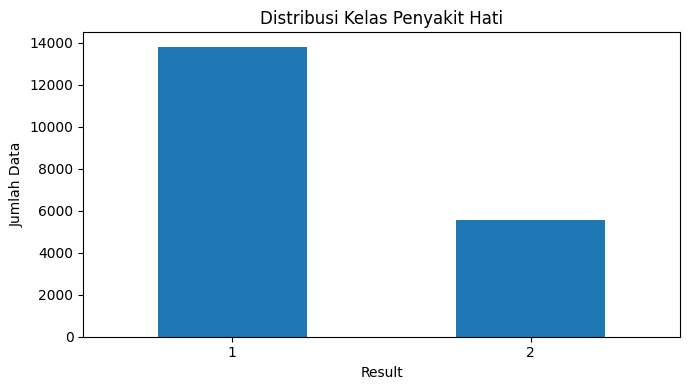

In [24]:
import matplotlib.pyplot as plt

df["Result"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Distribusi Kelas Penyakit Hati")
plt.xlabel("Result")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

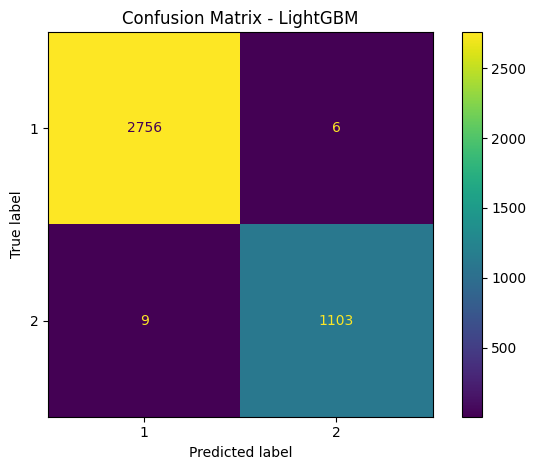

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(values_format="d")
plt.title("Confusion Matrix - LightGBM")
plt.tight_layout()
plt.show()

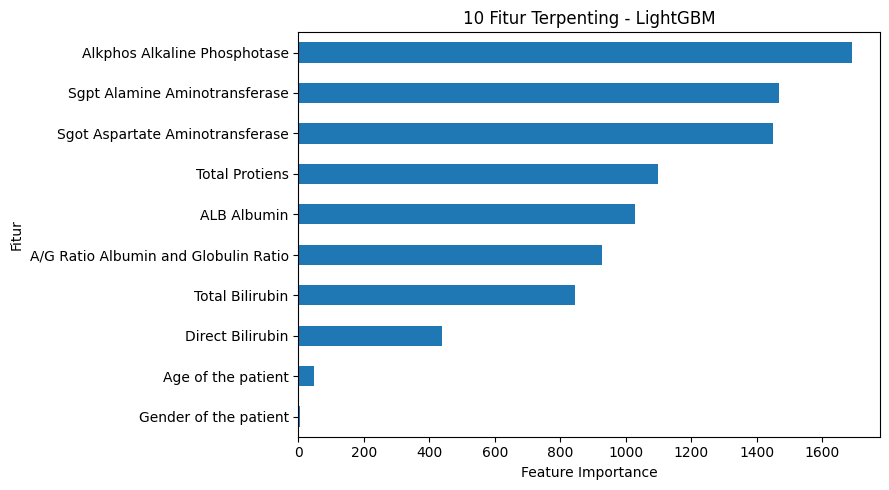

In [26]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True).tail(10)

importance.plot(kind="barh", figsize=(9, 5))

plt.title("10 Fitur Terpenting - LightGBM")
plt.xlabel("Feature Importance")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()

In [27]:
import joblib

joblib.dump({
    "model": model,
    "feature_columns": X_train.columns.tolist(),
    "target_column": "Result"
}, "lightgbm_liver_model.pkl")

print("Model berhasil disimpan!")

Model berhasil disimpan!


In [28]:
from sklearn.metrics import classification_report

print("Akurasi training:",
      model.score(X_train, y_train))

print("\nAkurasi testing:",
      model.score(X_test, y_test))

print("\nLaporan klasifikasi:")
print(classification_report(y_test, y_pred))

Akurasi training: 0.9994836710984898

Akurasi testing: 0.9961280330407847

Laporan klasifikasi:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00      2762
           2       0.99      0.99      0.99      1112

    accuracy                           1.00      3874
   macro avg       1.00      0.99      1.00      3874
weighted avg       1.00      1.00      1.00      3874

